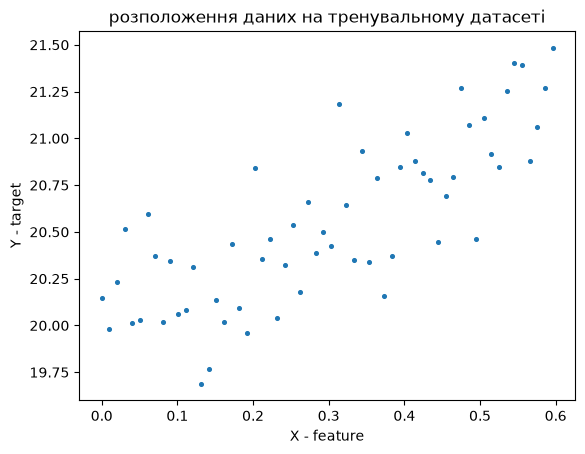

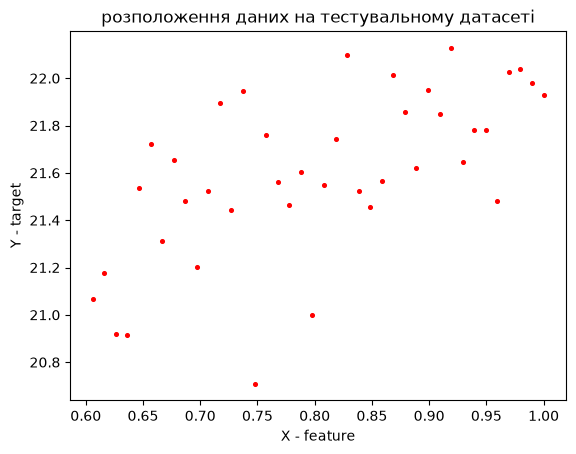

In [39]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True, precision=6)

loaded_arr = np.loadtxt('lab_1_train.csv', delimiter=',', skiprows=1, usecols=(1, 2), dtype=float)

x = loaded_arr[:, 0]
y = loaded_arr[:, 1]

plt.scatter(x, y, s=7)
plt.title("розположення даних на тренувальному датасеті")
plt.xlabel("X - feature")
plt.ylabel("Y - target")

loaded_arr1 = np.loadtxt('lab_1_test.csv', delimiter=',', skiprows=1, usecols=(1, 2), dtype=float)

x1 = loaded_arr1[:, 0]
y1 = loaded_arr1[:, 1]

plt.figure()

plt.scatter(x1, y1, s=7, color = (1, 0 ,0))
plt.title("розположення даних на тестувальному датасеті")
plt.xlabel("X - feature")
plt.ylabel("Y - target")

plt.show()

m = len(x)
w0 = 0.2
b0 = 12.0
lim = 1500
tol = 1e-9
alpha = [0.05, 0.1, 0.2]
w_test = 1.986353 
b_test = 19.957605

Завдання b:
Після кожної епохи виводити поточні значення ваг та функції втрат. Використовувати Mean Squared Error як функцію втрат.

In [40]:
def Derivative (x, y, m, w, b):
    h_list = []
    p_list = []
    z_list = []
    for n in range(len(x)):
        h_prog = b + x[n] * w
        h_list.append(h_prog)

    for k in range(len(x)):
        p = (h_list[k] - y[k]) * x[k]
        p_list.append(p)
        z = (h_list[k] - y[k])
        z_list.append(z)

    grad_w = 1/m * np.sum(p_list)
    grad_b = 1/m * np.sum(z_list)
    return grad_w, grad_b


def Theta_new (grad_w, grad_b, alpha, w, b):
    new_w = w - alpha * grad_w
    new_b = b - alpha * grad_b
    return new_w, new_b

def loss_function (w, b, x, y, m):
    h_new = []
    p_list = []
    for n in range(len(x)):
        h_prog = b + x[n] * w
        h_new.append(h_prog)

    for k in range(len(x)):
        p = (h_new[k] - y[k]) ** 2
        p_list.append(p)

    loss = 1/(2*m) * np.sum(p_list) 
    return loss


def Gradient_despent(x, y, m, alpha, w0, b0, lim, tol):
    results = {}
    for a in alpha:
        w, b =  w0, b0
        epoch = 0
        prev_loss = np.inf
        loss_history = []   
        while epoch < lim:
            grad_w, grad_b = Derivative (x, y, m, w, b)
            w, b = Theta_new (grad_w, grad_b, a, w, b)
            loss = loss_function (w, b, x, y, m)
            loss_history.append(loss)
            print(f"alpha={a} epoch={epoch} w={w:.6f} b={b:.6f} loss={loss:.6f}")
            if abs(prev_loss - loss) < tol:
                break
            prev_loss = loss
            epoch += 1
        results[a] = (w, b, loss_history)
    return results


results = Gradient_despent(x, y, m, alpha, w0, b0, lim, tol)

print ("=" * 100)
for a, (w, b, history) in results.items():
    print(f"alpha={a} epochs={len(history)} w={w:.6f} b={b:.6f} loss={history[-1]:.6f}")

alpha=0.05 epoch=0 w=0.329214 b=12.424498 loss=32.294241
alpha=0.05 epoch=1 w=0.451331 b=12.825847 loss=28.870413
alpha=0.05 epoch=2 w=0.566740 b=13.205308 loss=25.810049
alpha=0.05 epoch=3 w=0.675806 b=13.564077 loss=23.074565
alpha=0.05 epoch=4 w=0.778876 b=13.903282 loss=20.629472
alpha=0.05 epoch=5 w=0.876277 b=14.223992 loss=18.443942
alpha=0.05 epoch=6 w=0.968318 b=14.527215 loss=16.490422
alpha=0.05 epoch=7 w=1.055292 b=14.813905 loss=14.744282
alpha=0.05 epoch=8 w=1.137476 b=15.084966 loss=13.183506
alpha=0.05 epoch=9 w=1.215130 b=15.341248 loss=11.788417
alpha=0.05 epoch=10 w=1.288502 b=15.583560 loss=10.541426
alpha=0.05 epoch=11 w=1.357827 b=15.812662 loss=9.426811
alpha=0.05 epoch=12 w=1.423324 b=16.029277 loss=8.430519
alpha=0.05 epoch=13 w=1.485202 b=16.234085 loss=7.539990
alpha=0.05 epoch=14 w=1.543660 b=16.427731 loss=6.743996
alpha=0.05 epoch=15 w=1.598884 b=16.610824 loss=6.032501
alpha=0.05 epoch=16 w=1.651050 b=16.783939 loss=5.396535
alpha=0.05 epoch=17 w=1.700325

Після того, як градієнтний спуск зійшовся, порахувати функцію втрат на тестових даних з lab1_test.csv.

0.03762885474637507


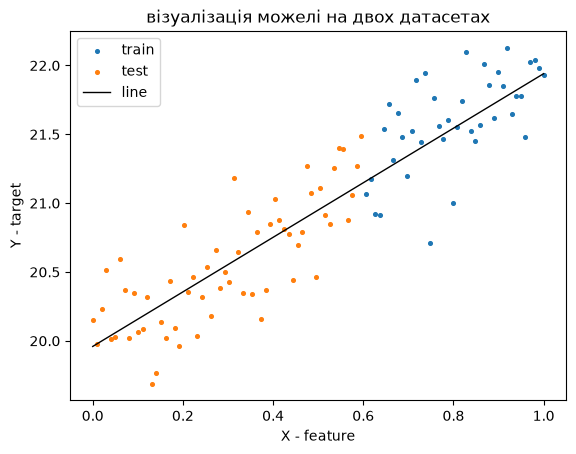

In [41]:
res = loss_function (w_test, b_test, x1, y1, len(x1))
print(res)

plt.figure()
plt.scatter(x1, y1, s=7, label="train")
plt.scatter(x, y, s=7, label="test")  
plt.plot([min(x.min(), x1.min()), max(x.max(), x1.max())], [b + w * min(x.min(), x1.min()), b + w * max(x.max(), x1.max())], color="black", linewidth=1, label="line")
plt.legend()
plt.title("візуалізація можелі на двох датасетах")
plt.xlabel("X - feature")
plt.ylabel("Y - target")
plt.show()
